In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)

Training dataset: 60000
Testing dataset: 10000
Image shape: torch.Size([1, 28, 28])


In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))

Number of classes: 10


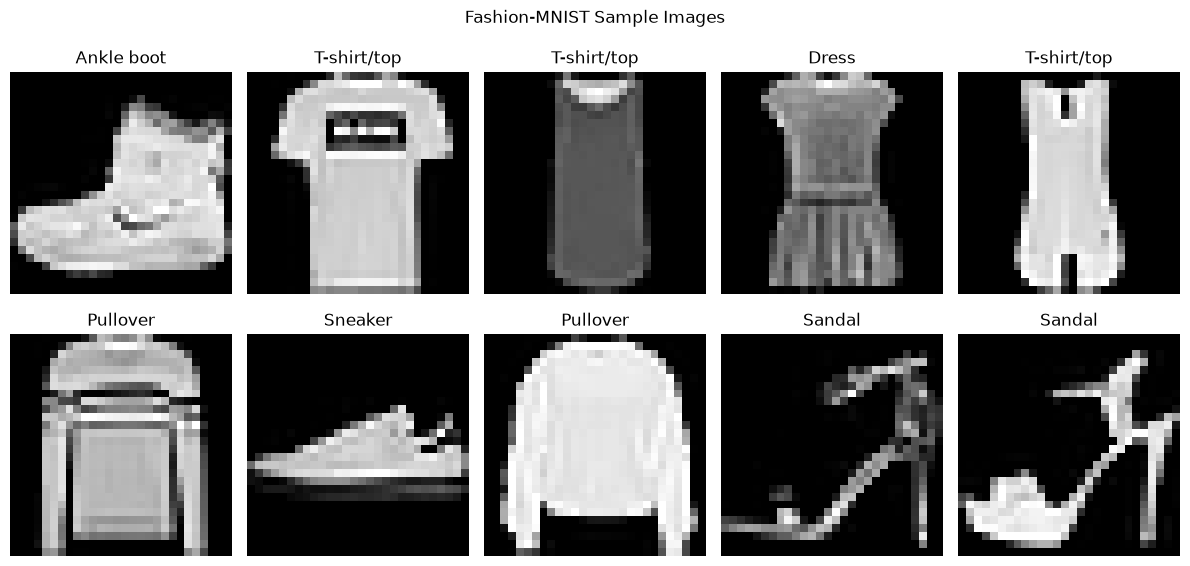

In [4]:
plt.figure(figsize=(12, 6))

for i in range(10):

    image, label = train_dataset[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(image.squeeze(), cmap="gray")

    plt.title(class_names[label])

    plt.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()

Selected class: Ankle boot
Image shape: (28, 28)


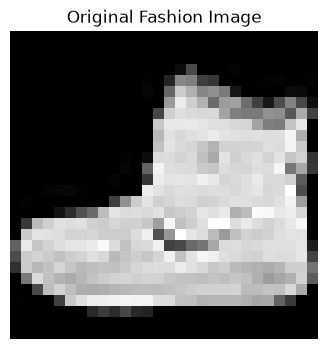

In [5]:
sample_image, sample_label = train_dataset[0]

image = sample_image.squeeze().numpy()

print("Selected class:", class_names[sample_label])
print("Image shape:", image.shape)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Original Fashion Image")
plt.axis("off")
plt.show()

In [6]:
def convolution_2d(image, kernel, stride=1):

    image_height, image_width = image.shape

    kernel_height, kernel_width = kernel.shape

    output_height = (
        (image_height - kernel_height) // stride
    ) + 1

    output_width = (
        (image_width - kernel_width) // stride
    ) + 1

    output = np.zeros((output_height, output_width))

    for i in range(output_height):

        for j in range(output_width):

            region = image[
                i * stride:i * stride + kernel_height,
                j * stride:j * stride + kernel_width
            ]

            output[i, j] = np.sum(region * kernel)

    return output

In [7]:
sobel_horizontal = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

print("Horizontal Sobel Filter:")
print(sobel_horizontal)

Horizontal Sobel Filter:
[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]


Original image shape: (28, 28)
Filtered image shape: (26, 26)


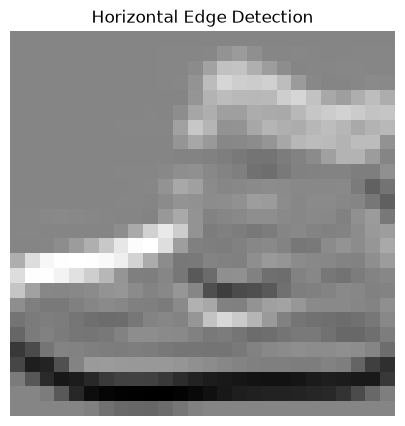

In [8]:
horizontal_output = convolution_2d(
    image,
    sobel_horizontal
)

print("Original image shape:", image.shape)
print("Filtered image shape:", horizontal_output.shape)

plt.figure(figsize=(5, 5))
plt.imshow(horizontal_output, cmap="gray")
plt.title("Horizontal Edge Detection")
plt.axis("off")
plt.show()

In [9]:
sobel_vertical = np.array([
    [-1,  0,  1],
    [-2,  0,  2],
    [-1,  0,  1]
])

print("Vertical Sobel Filter:")
print(sobel_vertical)

Vertical Sobel Filter:
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]


Vertical output shape: (26, 26)


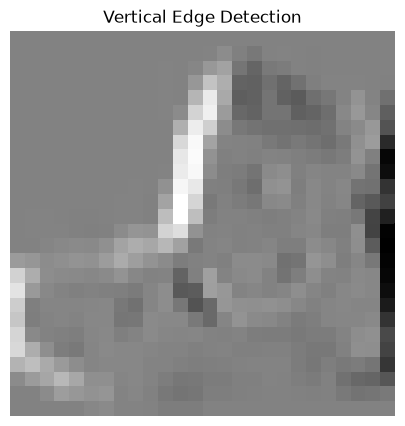

In [10]:
vertical_output = convolution_2d(
    image,
    sobel_vertical
)

print("Vertical output shape:", vertical_output.shape)

plt.figure(figsize=(5, 5))
plt.imshow(vertical_output, cmap="gray")
plt.title("Vertical Edge Detection")
plt.axis("off")
plt.show()

In [11]:
blur_filter = np.ones((3, 3)) / 9

print("3x3 Blur Filter:")
print(blur_filter)

3x3 Blur Filter:
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


Blur output shape: (26, 26)


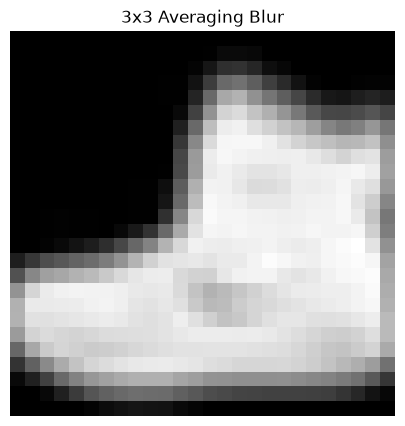

In [12]:
blur_output = convolution_2d(
    image,
    blur_filter
)

print("Blur output shape:", blur_output.shape)

plt.figure(figsize=(5, 5))
plt.imshow(blur_output, cmap="gray")
plt.title("3x3 Averaging Blur")
plt.axis("off")
plt.show()

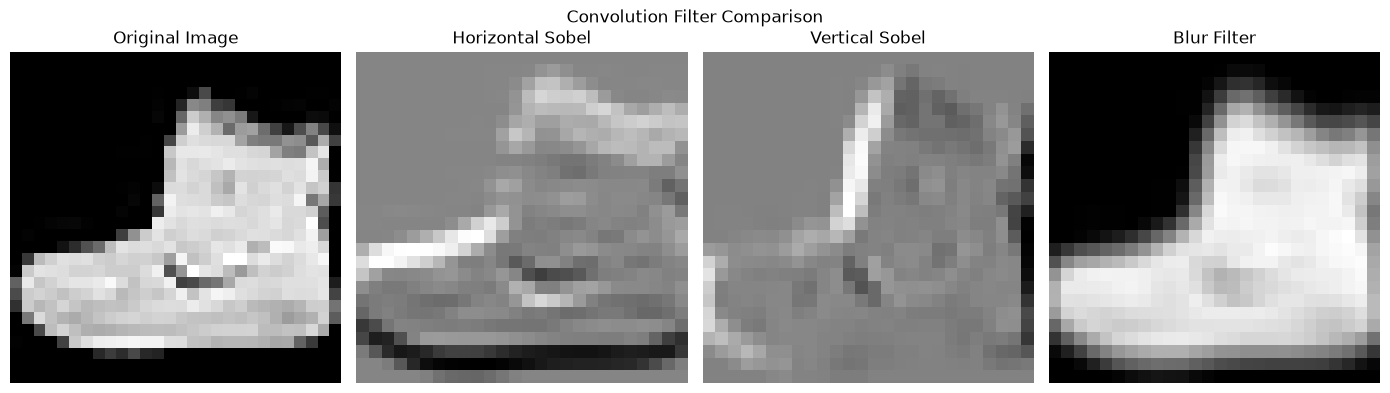

In [13]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(horizontal_output, cmap="gray")
plt.title("Horizontal Sobel")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(vertical_output, cmap="gray")
plt.title("Vertical Sobel")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(blur_output, cmap="gray")
plt.title("Blur Filter")
plt.axis("off")

plt.suptitle("Convolution Filter Comparison")
plt.tight_layout()
plt.show()

In [14]:
input_size = 28
kernel_size = 3
stride = 1
padding = 0

output_size = (
    (input_size - kernel_size + 2 * padding) // stride
) + 1

print("Input image size:", input_size, "x", input_size)
print("Kernel size:", kernel_size, "x", kernel_size)
print("Stride:", stride)
print("Padding:", padding)
print("Output size:", output_size, "x", output_size)

Input image size: 28 x 28
Kernel size: 3 x 3
Stride: 1
Padding: 0
Output size: 26 x 26
